# Olist E-Ticaret: Sipariş Anında Müşteri Memnuniyetsizliği ve Düşük Değerlendirme Riski Tahmini

**Proje Amacı:** E-ticaret operasyonlarında müşteri memnuniyetsizliğine (1 ve 2 yıldızlı düşük değerlendirmelere), şikayetlere ve olası tersine lojistik maliyetlerine yol açabilecek riskli siparişleri, **veri sızıntısı (data leakage) olmadan henüz sipariş onaylandığı anda (at order time)** makine öğrenmesi ile tespit etmek.

Bu projede Brezilyalı e-ticaret platformu Olist'in gerçek sipariş verilerini (6 ana ilişkisel tablo ve 1 kategori çeviri tablosunun birleşimiyle oluşan **110.840 ürün kalemi satırı / 96.478 tekil teslim edilmiş sipariş**) kullanarak operasyonel darboğazları analiz ettim ve müşteri memnuniyetini korumaya yönelik proaktif bir karar destek ve erken uyarı modeli geliştirdim.

### 1. Veri Tedariği, İlişkisel Veri Modelleme ve Veri Sızıntısının Önlenmesi
Olist'in ilişkisel veri tabanı mimarisinde parçalı halde tutulan **6 ana ilişkisel tabloyu** (`orders`, `customers`, `order_items`, `products`, `reviews`, `sellers`) ve Portekizce ürün kategorilerini İngilizceye çeviren **1 yardımcı çeviri tablosunu** (`product_category_name_translation`) ortak anahtarlar (`order_id`, `customer_id`, `product_id`, `seller_id`) üzerinden birleştirerek tek bir analitik veri çerçevesine (`df_main`: **110.840 satır**) dönüştürdüm.

**Metodolojik Düzeltme (Veri Sızıntısı / Data Leakage Engeli):**
* Gerçek teslimat tarihi (`order_delivered_customer_date`) ile tahmini teslimat tarihi arasındaki farkı gösteren `delivery_delay_days` değişkeni **yalnızca keşifsel veri analizi (EDA) ve kök neden analizinde** geçmiş durumu incelemek amacıyla hesaplanmıştır. Sipariş henüz verildiğinde gerçek teslimat tarihi bilinemeyeceği için bu değişken **tahmin modellerinin hiçbirinde girdi (feature) olarak kullanılmamıştır.**
* Bunun yerine, sipariş onaylandığı anda bilinen **Tahmini Teslimat Süresi (`estimated_delivery_days`)** ve **Siparişteki Ürün Kalemi Sayısı (`order_item_count`)** özellikleri türetilmiştir.

In [1]:
import pandas as pd
import numpy as np

# 1. Veri setlerini okuma (6 ana ilişkisel tablo + 1 kategori çeviri tablosu)
df_orders = pd.read_csv('../data/olist_orders_dataset.csv')
df_items = pd.read_csv('../data/olist_order_items_dataset.csv')
df_products = pd.read_csv('../data/olist_products_dataset.csv')
df_translation = pd.read_csv('../data/product_category_name_translation.csv')
df_reviews = pd.read_csv('../data/olist_order_reviews_dataset.csv')
df_customers = pd.read_csv('../data/olist_customers_dataset.csv')
df_sellers = pd.read_csv('../data/olist_sellers_dataset.csv')

# 2. Portekizce kategorileri İngilizceye çevirmek için products ve translation birleştirilir
df_products = df_products.merge(df_translation, on='product_category_name', how='left')

# 3. İlgili tüm tabloları 'order_id', 'customer_id', 'product_id' ve 'seller_id' etrafında birleştirme
df_main = df_orders.merge(df_customers, on='customer_id', how='inner')
df_main = df_main.merge(df_reviews, on='order_id', how='left')
df_main = df_main.merge(df_items, on='order_id', how='inner')
df_main = df_main.merge(df_products, on='product_id', how='left')
df_main = df_main.merge(df_sellers, on='seller_id', how='left')

# 4. Sadece 'teslim edilmiş' (delivered) siparişleri filtreleme
df_main = df_main[df_main['order_status'] == 'delivered'].copy()

# 5. Tarih sütunlarını datetime formatına çevirme
date_columns = [
    'order_purchase_timestamp', 
    'order_approved_at', 
    'order_delivered_carrier_date', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]
for col in date_columns:
    df_main[col] = pd.to_datetime(df_main[col])

# 6. EDA Analizi İçin Gerçekleşen Gecikme Süresi (Veri sızıntısını önlemek adına model girdilerinde KULLANILMAZ!)
df_main['delivery_delay_days'] = (df_main['order_delivered_customer_date'] - df_main['order_estimated_delivery_date']).dt.days

# 7. Sipariş Anında Bilinen Özellik Mühendisliği (Sızıntısız / Zero Data Leakage)
df_main['estimated_delivery_days'] = (df_main['order_estimated_delivery_date'] - df_main['order_purchase_timestamp']).dt.days
df_main['order_item_count'] = df_main.groupby('order_id')['order_item_id'].transform('count')

print(f"Birleştirilmiş teslim edilen sipariş verisi boyutu (ürün kalemi bazında): {df_main.shape}")
print(f"Tekil sipariş (order_id) sayısı: {df_main['order_id'].nunique()}")
display(df_main.head(3))

Birleştirilmiş teslim edilen sipariş verisi boyutu (ürün kalemi bazında): (110840, 39)
Tekil sipariş (order_id) sayısı: 96478


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,delivery_delay_days,estimated_delivery_days,order_item_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,19.0,8.0,13.0,housewares,9350,maua,SP,-8.0,15,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,19.0,13.0,19.0,perfumery,31570,belo horizonte,SP,-6.0,19,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,24.0,19.0,21.0,auto,14840,guariba,SP,-18.0,26,1


### 2. Hedef Değişkenin (`is_risk`) Tanımlanması ve Keşifsel Gecikme Analizi (EDA)
Olist veri setinde doğrulanmış bir ürün iade etiketi yer almadığından, işletme açısından müşteri kaybı ve şikayet krizini temsil eden **Düşük Müşteri Değerlendirmesi / Memnuniyetsizlik Riski** hedef değişken olarak tanımlanmıştır:
* **1 ve 2 yıldız (`review_score <= 2`):** Riskli / Memnuniyetsiz Müşteri (`is_risk = 1`)
* **3, 4 ve 5 yıldız (`review_score > 2`):** Sorunsuz / Memnun Müşteri (`is_risk = 0`)

Aşağıdaki keşifsel analizde (EDA), geçmiş siparişlerde gerçekleşen teslimat gecikmesinin müşteri memnuniyetsizliğini nasıl tetiklediği incelenmiştir. *(Not: `delivery_delay_days` yalnızca bu keşifsel grafikte kullanılmış olup tahmin modellerine dahil edilmemiştir.)*

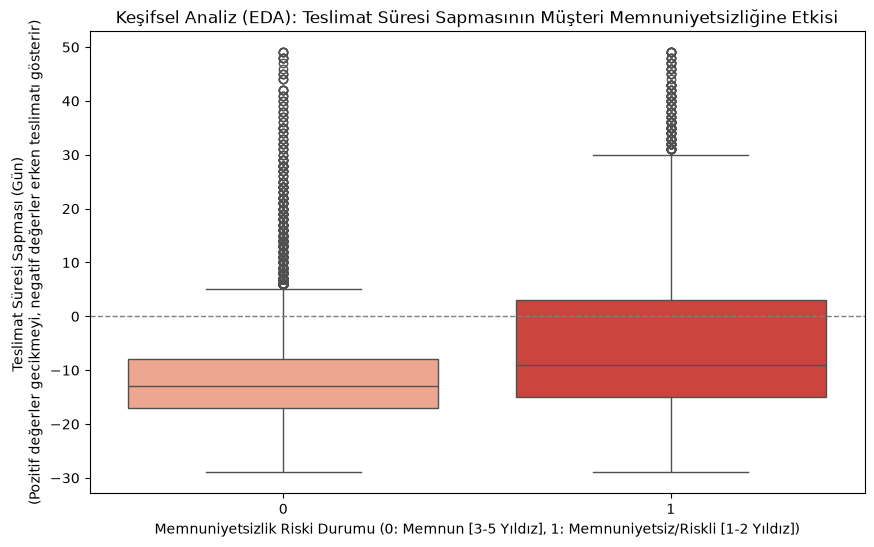

Toplam 110840 sipariş kalemi içindeki memnuniyetsizlik riski (1-2 yıldız) oranı: %14.68


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Hedef Değişkeni (Target) Oluşturma: review_score 1 veya 2 ise riskli/memnuniyetsiz (1), değilse sorunsuz (0)
df_main['is_risk'] = df_main['review_score'].apply(lambda x: 1 if x <= 2 else 0)

# 2. Keşifsel Analiz (EDA): Geçmiş veride gecikme süresi ile memnuniyetsizlik arasındaki ilişki
df_plot = df_main[(df_main['delivery_delay_days'] > -30) & (df_main['delivery_delay_days'] < 50)]

plt.figure(figsize=(10, 6))
sns.boxplot(x='is_risk', y='delivery_delay_days', hue='is_risk', data=df_plot, palette='Reds', legend=False)
plt.title('Keşifsel Analiz (EDA): Teslimat Süresi Sapmasının Müşteri Memnuniyetsizliğine Etkisi')
plt.xlabel('Memnuniyetsizlik Riski Durumu (0: Memnun [3-5 Yıldız], 1: Memnuniyetsiz/Riskli [1-2 Yıldız])')
plt.ylabel('Teslimat Süresi Sapması (Gün) \n(Pozitif değerler gecikmeyi, negatif değerler erken teslimatı gösterir)')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.show()

# 3. Genel memnuniyetsizlik riski oranını hesaplayalım
risk_rate = df_main['is_risk'].mean() * 100
print(f"Toplam {len(df_main)} sipariş kalemi içindeki memnuniyetsizlik riski (1-2 yıldız) oranı: %{risk_rate:.2f}")

### 3. Sipariş Anı Özellik Seçimi, Eksik Veri Raporu ve Korelasyon Analizi
Modelin **sipariş onaylandığı anda** çalışabilmesi için yalnızca sipariş anında bilinen sayısal değişkenler seçilmiştir:
* `estimated_delivery_days`: Müşteriye taahhüt edilen tahmini teslimat süresi (gün)
* `order_item_count`: Siparişte yer alan toplam ürün kalemi adedi
* `freight_value`: Kargo ücreti
* `price`: Ürün fiyatı
* `product_weight_g`: Ürün ağırlığı (gram)
* `product_photos_qty`: Ürün fotoğraf sayısı

**Eksik Veri (Missing Data) Stratejisi ve Raporu:**
110.840 satırlık veri setinde ürün ağırlığı (`product_weight_g`: 18 eksik satır), ürün fotoğraf adedi (`product_photos_qty`: 1.545 eksik satır) ve kategori adı (`product_category_name_english`: 1.567 eksik satır) bilgisi bulunmayan kayıtlar incelenmiştir. Eksik ürün metaverisine sahip satırlar tüm veri setinin yalnızca **%1,41'ini** oluşturduğu için yapay gürültü eklememek adına `dropna()` ile temizlenmiş ve kaç satırın hangi sütunlar nedeniyle elendiği şeffafça raporlanmıştır (Sayısal modelleme verisi: **109.294 satır**, Kategorik modelleme verisi: **109.272 satır / 95.126 tekil sipariş**).

--- Eksik Veri (NaN) Raporu ---
order_id                            0
is_risk                             0
estimated_delivery_days             0
order_item_count                    0
freight_value                       0
price                               0
product_weight_g                   18
product_photos_qty               1545
product_category_name_english    1567
dtype: int64

Sayısal modelleme için temizlenen satır sayısı: 1546 (%1.39)
Sayısal modelleme için kalan temiz veri boyutu: (109294, 8)


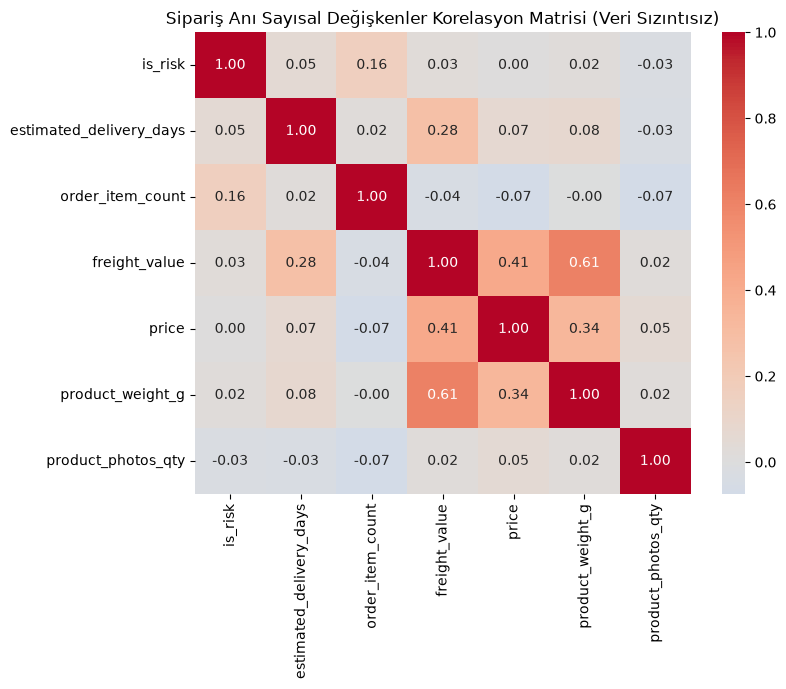

In [3]:
# Sipariş anında bilinen (Veri Sızıntısız) sayısal değişkenler
numeric_features = [
    'order_id',
    'is_risk', 
    'estimated_delivery_days', 
    'order_item_count',
    'freight_value', 
    'price', 
    'product_weight_g', 
    'product_photos_qty'
]

# Eksik veri raporu (Hangi sütunda kaç eksik değer var?)
print("--- Eksik Veri (NaN) Raporu ---")
print(df_main[numeric_features + ['product_category_name_english']].isna().sum())

# Eksik ürün metaverisine sahip satırların temizlenmesi (%1.40 oranında satır)
df_ml = df_main[numeric_features].dropna().copy()
dropped_num = len(df_main) - len(df_ml)
print(f"\nSayısal modelleme için temizlenen satır sayısı: {dropped_num} (%{dropped_num/len(df_main)*100:.2f})")
print(f"Sayısal modelleme için kalan temiz veri boyutu: {df_ml.shape}")

# Değişkenler arasındaki korelasyonu ısı haritası ile görselleştirelim
plt.figure(figsize=(8, 6))
sns.heatmap(df_ml.drop('order_id', axis=1).corr(), annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title('Sipariş Anı Sayısal Değişkenler Korelasyon Matrisi (Veri Sızıntısız)')
plt.show()

### 4. Sipariş Bazlı Veri Bölme (`GroupShuffleSplit`) ve Sayısal Random Forest Modelleri
Bir sipariş (`order_id`) birden fazla ürün kalemi içerebildiğinden, rastgele satır bölmesi (`train_test_split`) yapmak aynı siparişin bir kaleminin eğitim, diğer kaleminin test kümesine düşmesine (grup sızıntısına) yol açar.

Bu metodolojik sorunu önlemek için **`GroupShuffleSplit`** kullanılmış ve aynı `order_id` değerine sahip tüm satırların yalnızca eğitim veya yalnızca test kümesinde yer alması garanti altına alınmıştır (Eğitim-Test sipariş kesişimi: **0**). İlk aşamada yalnızca sayısal değişkenlerle varsayılan Random Forest ve `class_weight='balanced'` parametreli Random Forest modelleri karşılaştırılmıştır.

Eğitim Seti: (87490, 6), Test Seti: (21804, 6) | Ortak Sipariş (order_id) Kesişimi: 0

--- İlk Random Forest Sınıflandırma Raporu (Sayısal Özellikler) ---
              precision    recall  f1-score   support

           0       0.86      0.97      0.91     18670
           1       0.27      0.07      0.11      3134

    accuracy                           0.84     21804
   macro avg       0.56      0.52      0.51     21804
weighted avg       0.78      0.84      0.80     21804



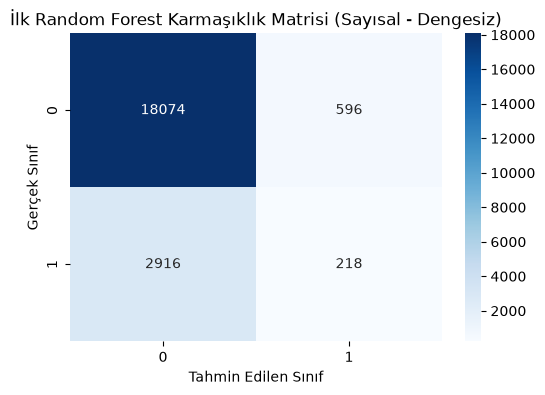

In [4]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Özellikler (X), Hedef Değişken (y) ve Sipariş Grubu (groups_num) ayrımı
X = df_ml.drop(['is_risk', 'order_id'], axis=1)
y = df_ml['is_risk']
groups_num = df_ml['order_id']

# Aynı order_id'nin hem eğitim hem test setine düşmesini engellemek için GroupShuffleSplit (%80 Eğitim, %20 Test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups_num))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = len(set(groups_num.iloc[train_idx]).intersection(set(groups_num.iloc[test_idx])))
print(f"Eğitim Seti: {X_train.shape}, Test Seti: {X_test.shape} | Ortak Sipariş (order_id) Kesişimi: {overlap}")

# İlk Random Forest Modelini Kurma ve Eğitme (Varsayılan ağırlıklar)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

print("\n--- İlk Random Forest Sınıflandırma Raporu (Sayısal Özellikler) ---")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('İlk Random Forest Karmaşıklık Matrisi (Sayısal - Dengesiz)')
plt.xlabel('Tahmin Edilen Sınıf')
plt.ylabel('Gerçek Sınıf')
plt.show()

--- Dengeli (class_weight='balanced') Sayısal Random Forest Raporu ---
              precision    recall  f1-score   support

           0       0.86      0.91      0.89     18670
           1       0.21      0.14      0.17      3134

    accuracy                           0.80     21804
   macro avg       0.54      0.53      0.53     21804
weighted avg       0.77      0.80      0.78     21804



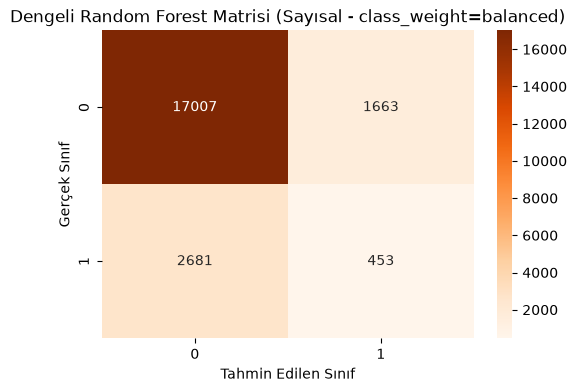

In [5]:
# Sınıf dengesizliğini gidermek üzere class_weight='balanced' ile modeli yeniden kuruyoruz
rf_model_balanced = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
rf_model_balanced.fit(X_train, y_train)
y_pred_balanced = rf_model_balanced.predict(X_test)

print("--- Dengeli (class_weight='balanced') Sayısal Random Forest Raporu ---")
print(classification_report(y_test, y_pred_balanced))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_balanced), annot=True, fmt='d', cmap='Oranges')
plt.title('Dengeli Random Forest Matrisi (Sayısal - class_weight=balanced)')
plt.xlabel('Tahmin Edilen Sınıf')
plt.ylabel('Gerçek Sınıf')
plt.show()

### Sayısal Modelin Karar Faktörleri (Feature Importance)
Sızıntı yaratan gecikme değişkeni çıkarıldıktan sonra, sipariş anında bilinen sayısal değişkenler arasında modelin hangi özelliklere ağırlık verdiğini (`feature_importances_`) inceliyoruz. Ürün fiyatı, kargo ücreti, tahmini teslimat süresi ve ürün ağırlığı temel belirleyiciler olarak öne çıkmaktadır.

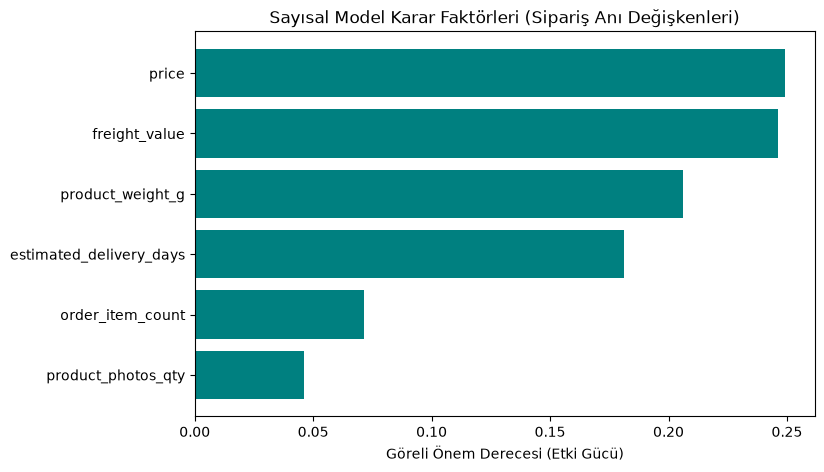

In [6]:
importances = rf_model_balanced.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(8, 5))
plt.title('Sayısal Model Karar Faktörleri (Sipariş Anı Değişkenleri)')
plt.barh(range(len(indices)), importances[indices], color='teal', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Göreli Önem Derecesi (Etki Gücü)')
plt.show()

### 5. İş Analitiği: Ürün Kategorilerine Göre Memnuniyetsizlik Riski
Sadece sayısal değişkenlerle (derinliği sınırlandırılmamış ağaçlarda) Recall oranının %14 seviyesinde kalması, memnuniyetsizlik riskinin lokasyon ve ürün kategorisi gibi bağlamsal değişkenlere güçlü biçimde bağlı olduğunu göstermektedir. Hangi ürün kategorilerinin oransal olarak en yüksek düşük değerlendirme (1-2 yıldız) riskine sahip olduğunu analiz ediyoruz.

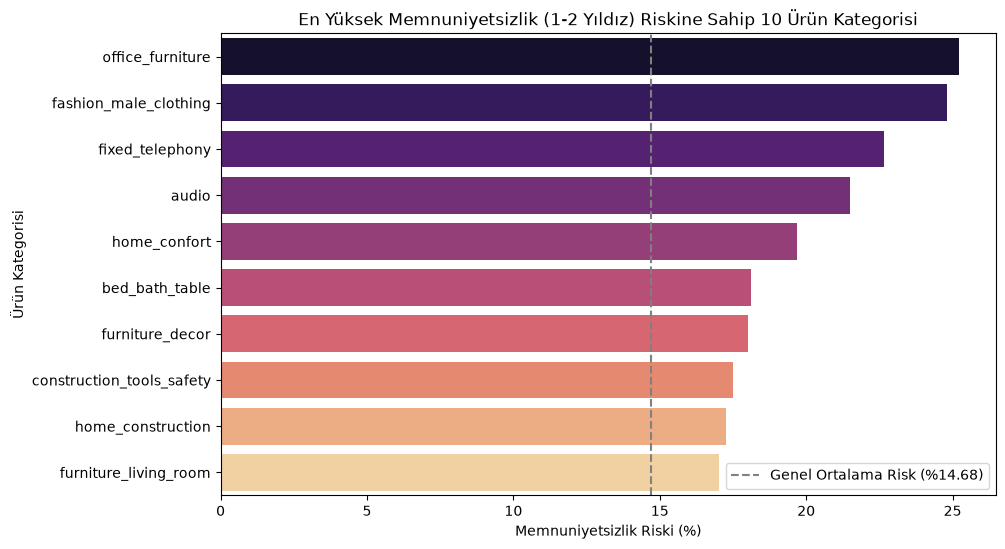

In [7]:
# Kategori bazlı memnuniyetsizlik risk oranını hesaplayalım (Minimum 50 siparişi olan kategoriler)
category_stats = df_main.groupby('product_category_name_english').agg(
    total_orders=('order_id', 'count'),
    risk_rate=('is_risk', 'mean')
)
top_risk_categories = category_stats[category_stats['total_orders'] > 50].sort_values(by='risk_rate', ascending=False).head(10)
top_risk_categories['risk_rate'] = top_risk_categories['risk_rate'] * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=top_risk_categories['risk_rate'], y=top_risk_categories.index, hue=top_risk_categories.index, palette='magma', legend=False)
plt.title('En Yüksek Memnuniyetsizlik (1-2 Yıldız) Riskine Sahip 10 Ürün Kategorisi')
plt.xlabel('Memnuniyetsizlik Riski (%)')
plt.ylabel('Ürün Kategorisi')
plt.axvline(risk_rate, color='gray', linestyle='--', label=f'Genel Ortalama Risk (%{risk_rate:.2f})')
plt.legend()
plt.show()

### 6. Hiperparametre Optimizasyonu (`RandomizedSearchCV`) ve SMOTE Deneyi
Karar ağaçlarının aşırı öğrenmesini (overfitting) engellemek ve azınlık sınıfı (memnuniyetsiz müşteriler) yakalama duyarı (`Recall`) artırmak için `RandomizedSearchCV` ile ağaç derinliği ve yaprak parametreleri optimize edilmiştir.

Ardından sentetik veri üretme tekniği olan **SMOTE** denenmiş, ancak e-ticaret verilerindeki iç içe geçmişlik nedeniyle SMOTE işleminin `class_weight='balanced'` yaklaşımına kıyasla Recall değerini düşürdüğü (hiperparametreleri optimize edilmiş, derinliği sınırlı modelde %38'den %25'e) gözlemlenerek nihai modelde algoritmik ağırlıklandırma (`class_weight='balanced'`) tercih edilmiştir.

In [8]:
from sklearn.model_selection import RandomizedSearchCV
from imblearn.over_sampling import SMOTE

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [15, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [2, 4]
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, class_weight='balanced'),
    param_distributions=param_dist,
    n_iter=10, 
    cv=3,      
    scoring='recall',
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV En İyi Parametreler (Sayısal): {random_search.best_params_}")

best_rf_model = random_search.best_estimator_
y_pred_best = best_rf_model.predict(X_test)
print("\n--- Hiperparametreleri Optimize Edilmiş Sayısal RF Raporu ---")
print(classification_report(y_test, y_pred_best))

# SMOTE Deneyi ve Karşılaştırması
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"Orijinal Eğitim Dağılımı: {y_train.value_counts().to_dict()} -> SMOTE Sonrası: {y_train_smote.value_counts().to_dict()}")

rf_smote = RandomForestClassifier(**random_search.best_params_, random_state=42, n_jobs=-1)
rf_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = rf_smote.predict(X_test)
print("\n--- SMOTE Sonrası Sınıflandırma Raporu (Recall Düşüşü Gözlemlendi) ---")
print(classification_report(y_test, y_pred_smote))

RandomizedSearchCV En İyi Parametreler (Sayısal): {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 15}

--- Hiperparametreleri Optimize Edilmiş Sayısal RF Raporu ---
              precision    recall  f1-score   support

           0       0.89      0.82      0.85     18670
           1       0.26      0.38      0.31      3134

    accuracy                           0.76     21804
   macro avg       0.57      0.60      0.58     21804
weighted avg       0.80      0.76      0.77     21804

Orijinal Eğitim Dağılımı: {0: 74647, 1: 12843} -> SMOTE Sonrası: {0: 74647, 1: 74647}

--- SMOTE Sonrası Sınıflandırma Raporu (Recall Düşüşü Gözlemlendi) ---
              precision    recall  f1-score   support

           0       0.88      0.88      0.88     18670
           1       0.26      0.25      0.26      3134

    accuracy                           0.79     21804
   macro avg       0.57      0.57      0.57     21804
weighted avg       0.79      0.79      0.79 

### 7. Kategorik Değişkenlerin Eklenmesi (One-Hot Encoding), Baseline Karşılaştırması ve Nihai Model
Sipariş anında bilinen **Müşteri Eyaleti (`customer_state`)**, **Satıcı Eyaleti (`seller_state`)** ve **Ürün Kategorisi (`product_category_name_english`)** değişkenleri `One-Hot Encoding` yöntemiyle modele dahil edilmiş ve toplam **123 özellikten** oluşan genişletilmiş analitik matris (`109.272 satır / 95.126 tekil sipariş`) elde edilmiştir.

Yine `GroupShuffleSplit` ile sipariş bazında ayrılan veri kümesi üzerinde:
1. **Baseline Model (Lojistik Regresyon):** Temel kıyaslama noktası olarak eğitilmiştir (Recall: %54, Precision: %23, F1: %32, Accuracy: %66). *Not: Özellikler ölçeklenmediği için Lojistik Regresyon 1.000 iterasyonda tam yakınsamamış (ConvergenceWarning); bu nedenle baseline sonuçları bir alt sınır olarak yorumlanmalıdır.*
2. **Nihai Random Forest Modeli (`n_estimators=300, max_depth=30, min_samples_split=5, min_samples_leaf=4, class_weight='balanced'`):** Varsayılan %50 (0.50) eşiğinde ve optimize edilmiş **%45 (0.45) karar eşiğinde** değerlendirilmiştir. 

Temizlenmiş Kategorik Veri Boyutu: (109272, 12) | One-Hot Encoding Sonrası Özellik Sayısı: 123
Eğitim Seti: (87328, 123), Test Seti: (21944, 123)


<venv>\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



--- Baseline Model (Lojistik Regresyon) Sınıflandırma Raporu ---
              precision    recall  f1-score   support

           0       0.89      0.69      0.78     18674
           1       0.23      0.54      0.32      3270

    accuracy                           0.66     21944
   macro avg       0.56      0.61      0.55     21944
weighted avg       0.80      0.66      0.71     21944


--- Nihai Random Forest Raporu (Varsayılan Eşik = 0.50) ---
              precision    recall  f1-score   support

           0       0.90      0.76      0.82     18674
           1       0.27      0.50      0.35      3270

    accuracy                           0.72     21944
   macro avg       0.58      0.63      0.59     21944
weighted avg       0.80      0.72      0.75     21944


--- Nihai Random Forest Raporu (Optimize Edilmiş Karar Eşiği = 0.45) ---
              precision    recall  f1-score   support

           0       0.91      0.64      0.75     18674
           1       0.24      0.63   

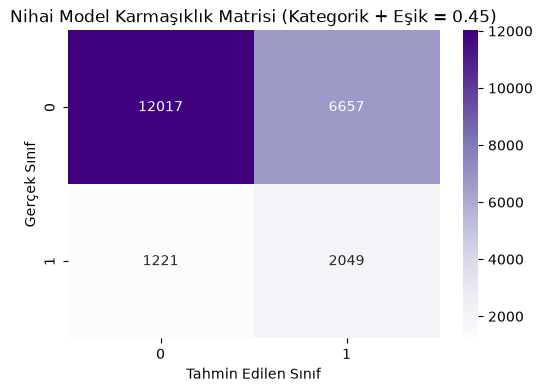

In [9]:
from sklearn.linear_model import LogisticRegression

# 1. Sipariş anında bilinen tüm sayısal ve kategorik değişkenler (delivery_delay_days ÇIKARILDI)
features_to_use = [
    'order_id', 'order_purchase_timestamp', 'is_risk',
    'estimated_delivery_days', 'order_item_count', 'freight_value', 'price', 'product_weight_g', 'product_photos_qty',
    'customer_state', 'seller_state', 'product_category_name_english'
]

df_ml_cat = df_main[features_to_use].dropna().copy()
y_cat = df_ml_cat['is_risk']
groups_cat = df_ml_cat['order_id']
X_cat_raw = df_ml_cat.drop(['is_risk', 'order_id', 'order_purchase_timestamp'], axis=1)

# 2. One-Hot Encoding
X_cat_encoded = pd.get_dummies(X_cat_raw, columns=['customer_state', 'seller_state', 'product_category_name_english'], drop_first=True)
print(f"Temizlenmiş Kategorik Veri Boyutu: {df_ml_cat.shape} | One-Hot Encoding Sonrası Özellik Sayısı: {X_cat_encoded.shape[1]}")

# 3. Sipariş Bazlı Eğitim/Test Ayrımı (GroupShuffleSplit)
gss_cat = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx_c, test_idx_c = next(gss_cat.split(X_cat_encoded, y_cat, groups=groups_cat))
X_train_c, X_test_c = X_cat_encoded.iloc[train_idx_c], X_cat_encoded.iloc[test_idx_c]
y_train_c, y_test_c = y_cat.iloc[train_idx_c], y_cat.iloc[test_idx_c]
print(f"Eğitim Seti: {X_train_c.shape}, Test Seti: {X_test_c.shape}")

# 4. Baseline Model: Lojistik Regresyon Karşılaştırması
lr_baseline = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr_baseline.fit(X_train_c, y_train_c)
y_pred_lr = lr_baseline.predict(X_test_c)
print("\n--- Baseline Model (Lojistik Regresyon) Sınıflandırma Raporu ---")
print(classification_report(y_test_c, y_pred_lr))

# 5. Nihai Şampiyon Model: Random Forest (Kategorik + Sayısal Özellikler)
rf_cat_model = RandomForestClassifier(
    n_estimators=300, 
    max_depth=30, 
    min_samples_split=5, 
    min_samples_leaf=4, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)
rf_cat_model.fit(X_train_c, y_train_c)

# Varsayılan %50 (0.50) Karar Eşiği Sonuçları
y_prob_c = rf_cat_model.predict_proba(X_test_c)[:, 1]
y_pred_c_50 = (y_prob_c >= 0.50).astype(int)
print("\n--- Nihai Random Forest Raporu (Varsayılan Eşik = 0.50) ---")
print(classification_report(y_test_c, y_pred_c_50))

# Optimize Edilmiş %45 (0.45) Karar Eşiği ile Tahmin
custom_threshold = 0.45
y_pred_c = (y_prob_c >= custom_threshold).astype(int)
print("\n--- Nihai Random Forest Raporu (Optimize Edilmiş Karar Eşiği = 0.45) ---")
print(classification_report(y_test_c, y_pred_c))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test_c, y_pred_c), annot=True, fmt='d', cmap='Purples')
plt.title('Nihai Model Karmaşıklık Matrisi (Kategorik + Eşik = 0.45)')
plt.xlabel('Tahmin Edilen Sınıf')
plt.ylabel('Gerçek Sınıf')
plt.show()

### 8. Model Doğrulama: 5-Fold Cross-Validation, ROC-AUC / PR-AUC Eğrileri ve Zamansal (Temporal) Test
Modelin metodolojik güvenilirliğini kanıtlamak adına üç aşamalı doğrulama gerçekleştirilmiştir:
1. **5-Fold StratifiedGroupKFold Cross-Validation:** Sipariş gruplarını koruyarak 5 katmanlı çapraz doğrulama uygulanmış, varsayılan 0.50 eşiğinde katman skorları [0.440, 0.482, 0.452, 0.459, 0.491] ve ortalama **%46,48 (±%1,91)** Recall istikrarı elde edilmiştir.
2. **ROC-AUC ve PR-AUC Analizi:** Nihai modelin **ROC-AUC skoru 0,6739**, sınıf dengesizliğinde kritik olan **PR-AUC (Average Precision) skoru 0,2715** (test kümesindeki rastgele tahmin tabanı olan 0,149'un yaklaşık 1,82 katı) olarak hesaplanmış ve eğrileri çizdirilmiştir.
3. **Zamansal (Temporal) Eğitim/Test Ayrımı:** Sipariş tarihine (`order_purchase_timestamp`) göre ilk %80'lik geçmiş dönem eğitim, son %20'lik gelecek dönem test olarak ayrıldığında modelin **ROC-AUC skoru 0,6269**, **PR-AUC skoru 0,1850** ve %45 eşiğinde **Recall oranı %53** (Precision %16) olarak gerçekleşmiştir. Rastgele bölmeye göre görülen performans düşüşü, zaman içindeki veri kaymasına (concept drift) işaret etmekte ve periyodik yeniden eğitim ihtiyacını göstermektedir.

--- 5-Fold StratifiedGroupKFold Sonuçları (Varsayılan Eşik = 0.50) ---
Katman (Fold) Recall Skorları: [0.44  0.482 0.452 0.459 0.491]
Ortalama Recall: %46.48 (±%1.91)

Test Seti ROC-AUC Skoru: 0.6739
Test Seti PR-AUC (Average Precision) Skoru: 0.2715


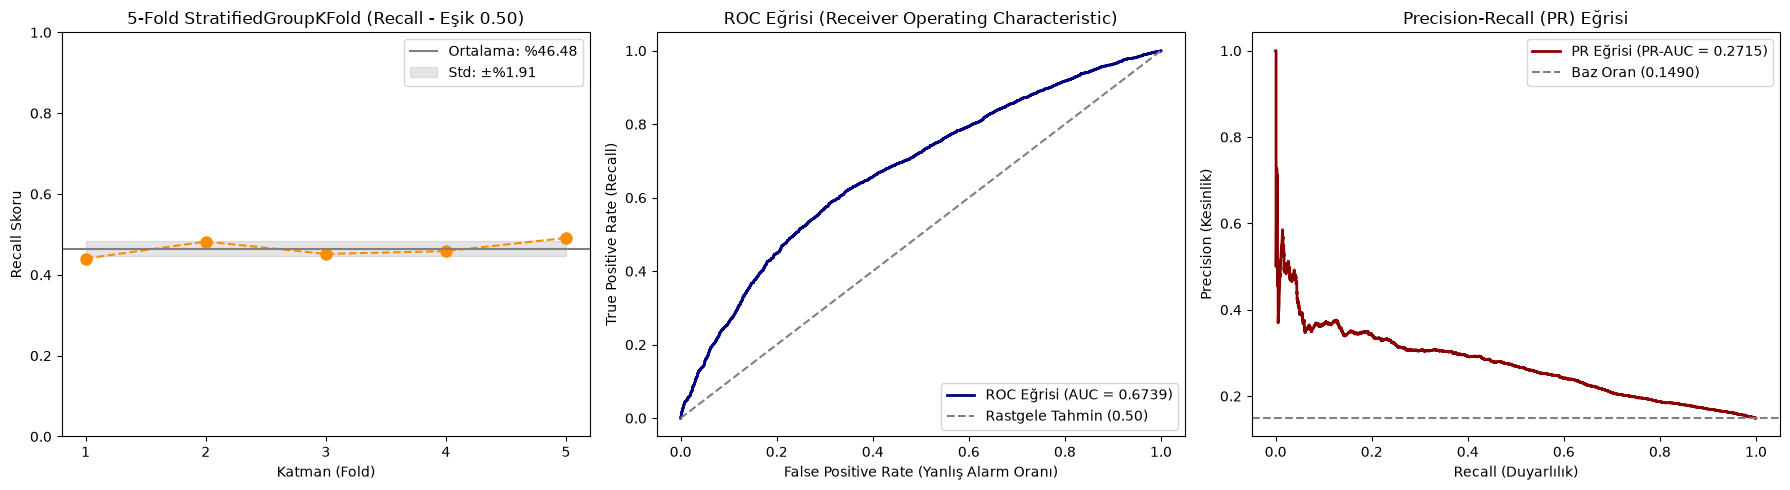


--- Zamansal (Temporal) Test Ayrımı Raporu (Kesim Tarihi: 2018-05-26, Eşik = 0.45) ---
              precision    recall  f1-score   support

           0       0.92      0.65      0.76     19371
           1       0.16      0.53      0.25      2480

    accuracy                           0.64     21851
   macro avg       0.54      0.59      0.51     21851
weighted avg       0.83      0.64      0.70     21851

Zamansal Test ROC-AUC: 0.6269 | PR-AUC: 0.1850


In [10]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

# 1. 5-Fold StratifiedGroupKFold Çapraz Doğrulama (Sipariş gruplarını koruyarak)
sgkf = StratifiedGroupKFold(n_splits=5)
cv_scores_cat = cross_val_score(rf_cat_model, X_cat_encoded, y_cat, groups=groups_cat, cv=sgkf, scoring='recall', n_jobs=-1)

print("--- 5-Fold StratifiedGroupKFold Sonuçları (Varsayılan Eşik = 0.50) ---")
print(f"Katman (Fold) Recall Skorları: {np.round(cv_scores_cat, 3)}")
print(f"Ortalama Recall: %{cv_scores_cat.mean()*100:.2f} (±%{cv_scores_cat.std()*100:.2f})")

# 2. ROC-AUC ve PR-AUC Hesaplaması ve Görselleştirilmesi
roc_auc_val = roc_auc_score(y_test_c, y_prob_c)
pr_auc_val = average_precision_score(y_test_c, y_prob_c)
print(f"\nTest Seti ROC-AUC Skoru: {roc_auc_val:.4f}")
print(f"Test Seti PR-AUC (Average Precision) Skoru: {pr_auc_val:.4f}")

fpr, tpr, _ = roc_curve(y_test_c, y_prob_c)
prec_curve, rec_curve, _ = precision_recall_curve(y_test_c, y_prob_c)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(range(1, 6), cv_scores_cat, marker='o', linestyle='--', color='darkorange', markersize=8)
axes[0].axhline(cv_scores_cat.mean(), color='gray', linestyle='-', label=f'Ortalama: %{cv_scores_cat.mean()*100:.2f}')
axes[0].fill_between(range(1, 6), cv_scores_cat.mean() - cv_scores_cat.std(), cv_scores_cat.mean() + cv_scores_cat.std(), color='gray', alpha=0.2, label=f'Std: ±%{cv_scores_cat.std()*100:.2f}')
axes[0].set_title('5-Fold StratifiedGroupKFold (Recall - Eşik 0.50)')
axes[0].set_xlabel('Katman (Fold)')
axes[0].set_ylabel('Recall Skoru')
axes[0].set_ylim(0, 1)
axes[0].set_xticks(range(1, 6))
axes[0].legend()

axes[1].plot(fpr, tpr, color='navy', lw=2, label=f'ROC Eğrisi (AUC = {roc_auc_val:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Rastgele Tahmin (0.50)')
axes[1].set_title('ROC Eğrisi (Receiver Operating Characteristic)')
axes[1].set_xlabel('False Positive Rate (Yanlış Alarm Oranı)')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right')

axes[2].plot(rec_curve, prec_curve, color='darkred', lw=2, label=f'PR Eğrisi (PR-AUC = {pr_auc_val:.4f})')
axes[2].axhline(y_test_c.mean(), color='gray', linestyle='--', label=f'Baz Oran ({y_test_c.mean():.4f})')
axes[2].set_title('Precision-Recall (PR) Eğrisi')
axes[2].set_xlabel('Recall (Duyarlılık)')
axes[2].set_ylabel('Precision (Kesinlik)')
axes[2].legend(loc='upper right')
plt.tight_layout()
plt.show()

# 3. Zamansal (Temporal) Eğitim-Test Ayrımı ile Genellenebilirlik Kontrolü
df_sorted = df_ml_cat.sort_values('order_purchase_timestamp')
cutoff_time = df_sorted['order_purchase_timestamp'].iloc[int(len(df_sorted) * 0.8)]
train_mask = (df_ml_cat['order_purchase_timestamp'] <= cutoff_time).values
test_mask = ~train_mask

rf_temp = RandomForestClassifier(
    n_estimators=300, max_depth=30, min_samples_split=5, min_samples_leaf=4,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_temp.fit(X_cat_encoded[train_mask], y_cat[train_mask])
y_prob_temp = rf_temp.predict_proba(X_cat_encoded[test_mask])[:, 1]
y_pred_temp = (y_prob_temp >= 0.45).astype(int)

print(f"\n--- Zamansal (Temporal) Test Ayrımı Raporu (Kesim Tarihi: {cutoff_time.strftime('%Y-%m-%d')}, Eşik = 0.45) ---")
print(classification_report(y_cat[test_mask], y_pred_temp))
print(f"Zamansal Test ROC-AUC: {roc_auc_score(y_cat[test_mask], y_prob_temp):.4f} | PR-AUC: {average_precision_score(y_cat[test_mask], y_prob_temp):.4f}")

### 9. İş Etkisi ve Varsayımsal Maliyet-Fayda (Cost-Benefit) Simülasyonu
Nihai modelimizin %45 karar eşiğinde test seti (`21.944 sipariş kalemi`) üzerinde ürettiği karmaşıklık matrisi (`TN: 12.017, FP: 6.657, FN: 1.221, TP: 2.049`), işletme kararlarını desteklemek amacıyla **varsayımsal birim maliyetler** üzerinden simüle edilmiştir:

* **Memnuniyetsizlik / Müşteri Kaybı Birim Zararı:** Memnuniyetsiz bir müşterinin yaratacağı olası iade, şikayet yönetimi ve müşteri kaybı (churn) maliyeti varsayımsal olarak **50 R$** kabul edilmiştir.
* **Proaktif Müdahale Maliyeti:** Riskli tahmin edilen siparişe gönderilecek telafi kuponu/iletişimi maliyeti **10 R$** kabul edilmiştir.
* **Önemli Metodolojik Varsayım Notu:** Temel simülasyonda yakalanan her gerçek riskli siparişte (`TP = 2.049`) proaktif müdahalenin memnuniyetsizliği önlediği varsayılmıştır. Gerçek dünyada bir indirim kuponunun her şikayeti %100 önlemesi garanti olmadığından, bu sonuçlar **gerçekleşmiş şirket kazancı değil, varsayımsal bir finansal projeksiyon** olarak değerlendirilmeli ve canlı ortamda A/B testleriyle doğrulanmalıdır.

--- VARSAYIMSAL FİNANSAL SİMÜLASYON (Test Seti: 21.944 Sipariş Kalemi) ---
Toplam Riskli Sipariş Sayısı (TP + FN): 3270
Modelin Yakaladığı Riskli Sipariş (True Positive - TP): 2049 (Recall: %62.66)
Kaçırılan Riskli Sipariş (False Negative - FN): 1221
Yanlış Alarm / Mutlu Müşteriye Kupon (False Positive - FP): 6657 (Precision: %23.54)

Modelsiz Varsayımsal Toplam Zarar: 163,500 R$
ML Modeli (%45 Eşik) ve Müdahale Stratejisinin Toplam Maliyeti: 148,110 R$
TEST SETİ VARSAYIMSAL NET TASARRUF (%45 Eşik - Maksimum Kriz Yakalama): +15,390 R$
TEST SETİ VARSAYIMSAL NET TASARRUF (%50 Eşik - Daha Az Yanlış Alarm): +20,990 R$


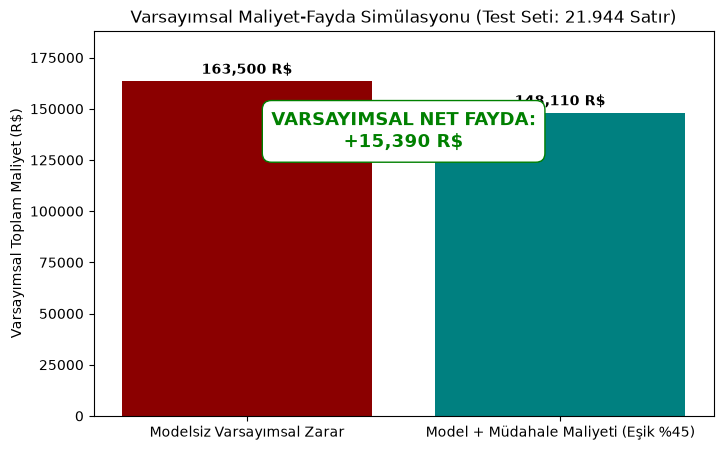

In [11]:
# 1. %45 Karar Eşiği Karmaşıklık Matrisi Çıktıları
tn, fp, fn, tp = confusion_matrix(y_test_c, y_pred_c).ravel()

# 2. Varsayımsal Birim Maliyetler
return_cost = 50   # Memnuniyetsizlik / olası iade ve müşteri kaybı varsayımsal birim zararı (50 R$)
discount_cost = 10 # Proaktif telafi kuponu varsayımsal birim maliyeti (10 R$)

# 3. Senaryo Hesaplamaları (Test Seti: 21.944 örnek)
baseline_cost = (tp + fn) * return_cost 
ml_model_cost = (tp * discount_cost) + (fp * discount_cost) + (fn * return_cost)
net_savings = baseline_cost - ml_model_cost

# Karşılaştırma için %50 Eşik Maliyeti
tn50, fp50, fn50, tp50 = confusion_matrix(y_test_c, y_pred_c_50).ravel()
net_savings_50 = baseline_cost - ((tp50 + fp50) * discount_cost + fn50 * return_cost)

print("--- VARSAYIMSAL FİNANSAL SİMÜLASYON (Test Seti: 21.944 Sipariş Kalemi) ---")
print(f"Toplam Riskli Sipariş Sayısı (TP + FN): {tp + fn}")
print(f"Modelin Yakaladığı Riskli Sipariş (True Positive - TP): {tp} (Recall: %{tp/(tp+fn)*100:.2f})")
print(f"Kaçırılan Riskli Sipariş (False Negative - FN): {fn}")
print(f"Yanlış Alarm / Mutlu Müşteriye Kupon (False Positive - FP): {fp} (Precision: %{tp/(tp+fp)*100:.2f})\n")

print(f"Modelsiz Varsayımsal Toplam Zarar: {baseline_cost:,.0f} R$")
print(f"ML Modeli (%45 Eşik) ve Müdahale Stratejisinin Toplam Maliyeti: {ml_model_cost:,.0f} R$")
print(f"TEST SETİ VARSAYIMSAL NET TASARRUF (%45 Eşik - Maksimum Kriz Yakalama): +{net_savings:,.0f} R$")
print(f"TEST SETİ VARSAYIMSAL NET TASARRUF (%50 Eşik - Daha Az Yanlış Alarm): +{net_savings_50:,.0f} R$")

plt.figure(figsize=(8, 5))
bars = plt.bar(['Modelsiz Varsayımsal Zarar', 'Model + Müdahale Maliyeti (Eşik %45)'], [baseline_cost, ml_model_cost], color=['darkred', 'teal'])
plt.title('Varsayımsal Maliyet-Fayda Simülasyonu (Test Seti: 21.944 Satır)')
plt.ylabel('Varsayımsal Toplam Maliyet (R$)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2000, f'{yval:,.0f} R$', ha='center', va='bottom', fontweight='bold')
plt.text(0.5, max(baseline_cost, ml_model_cost)*0.85, f'VARSAYIMSAL NET FAYDA:\n+{net_savings:,.0f} R$', 
         ha='center', va='center', fontsize=13, color='green', fontweight='bold',
         bbox=dict(facecolor='white', edgecolor='green', boxstyle='round,pad=0.5'))
plt.ylim(0, max(baseline_cost, ml_model_cost) * 1.15)
plt.show()

### 10. Kök Neden Analizi ve Kategori Bazlı İstatistiksel Güven Aralıkları
En yüksek memnuniyetsizlik oranına sahip kategorilerden **Ofis Mobilyaları (`office_furniture`)** ve **Erkek Giyim (`fashion_male_clothing`)**, diğer kategorilerle operasyonel metrikler ve **%95 güven aralıkları (Confidence Interval)** üzerinden karşılaştırılmıştır:

* **Akademik Ayrım (Gözlem vs. Hipotez):** Bu grafikler ve istatistikler memnuniyetsizliğin kesin nedenini tek başına kanıtlamaz; kategoriler arasındaki operasyonel farklılıkları ortaya koyarak araştırılması gereken iş hipotezlerini yönlendirir:
  1. **Ofis Mobilyası Analizi:** Ortalama ürün ağırlığı (**11.348,7 gram / ~11,3 kg**) diğer kategorilerin (**1.947,1 gram**) yaklaşık **5,8 katı**, kargo ücreti (**40,1 R$**) ise yaklaşık **2 katıdır**. Ortalama teslimat süresi sapması (-11,8 gün) diğer kategorilerden (-12,0 gün) yalnızca 0,2 gün farklıdır. Dolayısıyla bu kategorideki yüksek memnuniyetsizlik (%25,21) doğrudan gecikmeyle değil; **ağır/hacimli ürünlerin taşınma zorlukları, hasar riski veya yüksek kargo maliyeti beklentisi** hipotezleriyle araştırılmalıdır.
  2. **Erkek Giyim Analizi:** Erkek giyim kategorisinde lojistik göstergeler diğer kategorilere göre daha olumlu olmasına rağmen (ortalama ağırlık **591,4 gram**, kargo ücreti **16,5 R$**, teslimat **-12,7 gün** ile 0,7 gün daha erken) risk oranının yüksek olması (**%24,80**), **ürün özellikleri, kumaş kalitesi ve beden uyumu (size chart)** gibi alternatif açıklamaların araştırılmasını gerektirmektedir.

--- Kategori Bazlı Memnuniyetsizlik Riski ve Operasyonel Metrikler Tablosu ---


,Kategori Grubu,Sipariş Kalemi (n),Risk Oranı (%),%95 Güven Aralığı,Ort. Gecikme Sapması (Gün),Ort. Kargo Ücreti (R$),Ort. Ürün Ağırlığı (Gram)
0,Ofis Mobilyası,1678,25.21,[%23.13 - %27.29],-11.8,40.1,11348.7
1,Erkek Giyim,125,24.80,[%17.23 - %32.37],-12.7,16.5,591.4
2,Diğer Tüm Kategoriler,109037,14.51,[%14.30 - %14.72],-12.0,19.6,1947.1


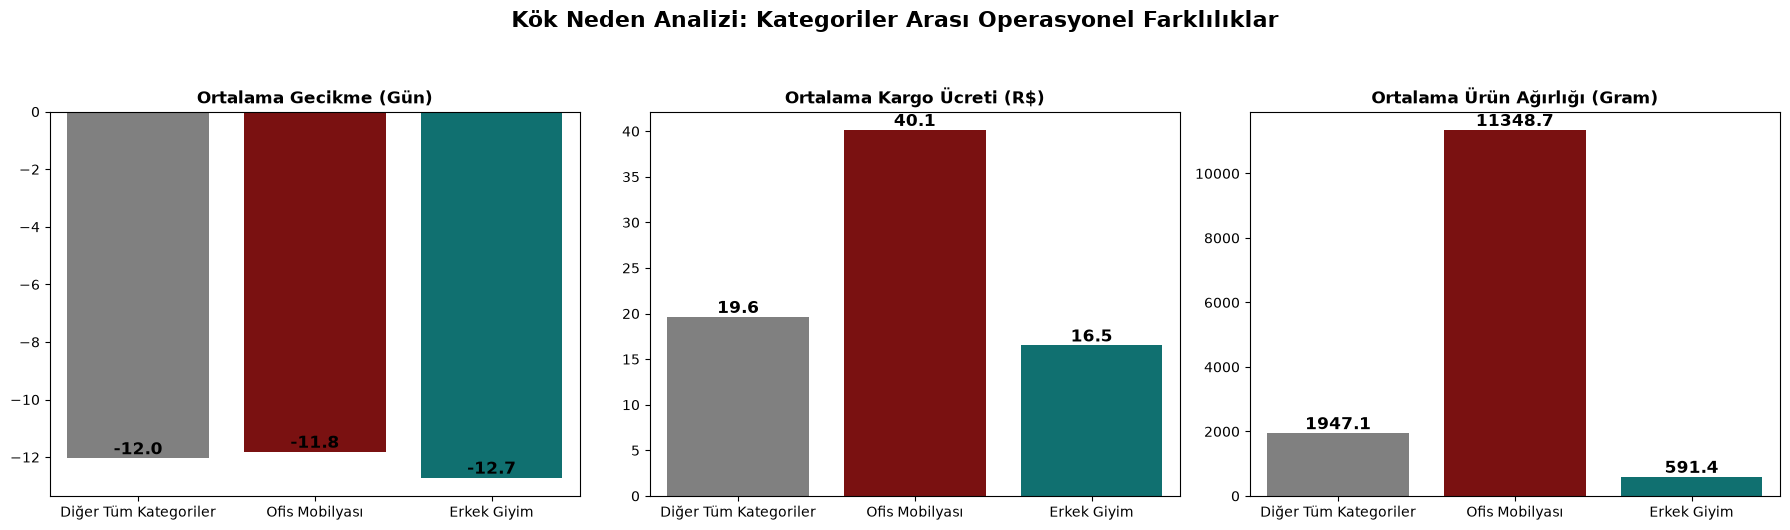

In [12]:
# 1. Kategori gruplarının oluşturulması
def group_category(cat):
    if cat == 'office_furniture':
        return 'Ofis Mobilyası'
    elif cat == 'fashion_male_clothing':
        return 'Erkek Giyim'
    else:
        return 'Diğer Tüm Kategoriler'

df_main['category_analysis'] = df_main['product_category_name_english'].apply(group_category)

# 2. Kategorilerin Risk Oranları ve %95 Güven Aralıkları (Confidence Intervals) Tablosu
summary_rows = []
for cat_name in ['Ofis Mobilyası', 'Erkek Giyim', 'Diğer Tüm Kategoriler']:
    grp = df_main[df_main['category_analysis'] == cat_name]
    n = len(grp)
    p = grp['is_risk'].mean()
    se = np.sqrt(p * (1 - p) / n)
    summary_rows.append({
        'Kategori Grubu': cat_name,
        'Sipariş Kalemi (n)': n,
        'Risk Oranı (%)': round(p * 100, 2),
        '%95 Güven Aralığı': f"[%{(p - 1.96*se)*100:.2f} - %{(p + 1.96*se)*100:.2f}]",
        'Ort. Gecikme Sapması (Gün)': round(grp['delivery_delay_days'].mean(), 1),
        'Ort. Kargo Ücreti (R$)': round(grp['freight_value'].mean(), 1),
        'Ort. Ürün Ağırlığı (Gram)': round(grp['product_weight_g'].mean(), 1)
    })
df_cat_table = pd.DataFrame(summary_rows)
print("--- Kategori Bazlı Memnuniyetsizlik Riski ve Operasyonel Metrikler Tablosu ---")
display(df_cat_table)

# 3. Operasyonel Farklılıkların Görselleştirilmesi
metrics = ['delivery_delay_days', 'freight_value', 'product_weight_g']
titles = ['Ortalama Gecikme (Gün)', 'Ortalama Kargo Ücreti (R$)', 'Ortalama Ürün Ağırlığı (Gram)']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, metric in enumerate(metrics):
    sns.barplot(
        x='category_analysis', 
        y=metric, 
        hue='category_analysis',
        data=df_main, 
        ax=axes[i], 
        palette={'Ofis Mobilyası': 'darkred', 'Erkek Giyim': 'teal', 'Diğer Tüm Kategoriler': 'gray'},
        errorbar=None,
        legend=False
    )
    axes[i].set_title(titles[i], fontweight='bold')
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')
    for p_patch in axes[i].patches:
        axes[i].annotate(f"{p_patch.get_height():.1f}", 
                         (p_patch.get_x() + p_patch.get_width() / 2., p_patch.get_height()), 
                         ha='center', va='bottom', fontsize=12, color='black', fontweight='bold')

plt.suptitle('Kök Neden Analizi: Kategoriler Arası Operasyonel Farklılıklar', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

### 11. Yıllık Finansal Projeksiyon ve Yatırım Getirisi (ROI) Simülasyonu
Test kümesi (`21.944 sipariş kalemi`) üzerindeki varsayımsal maliyet-fayda simülasyonunun (`+15.390 R$` net fayda, %50 eşikte `+20.990 R$`) yıllık **500.000 sipariş hacmine** ölçeklenmesiyle kurumsal düzeyde bir finansal projeksiyon oluşturulmuştur.

* **Akademik ve Finansal Çerçeve:** Yıllık 500.000 sipariş hacmi, 50.000 R$ varsayımsal sistem/teknoloji maliyeti ve telafi müdahalesinin başarı oranı gerçek operasyon verileriyle henüz doğrulanmadığı için; hesaplanan **+350.665 R$ yıllık brüt tasarruf**, **+300.665 R$ yıllık net kazanç potansiyeli** ve **%601 ROI** değerleri gerçekleşmiş gelir değil, **varsayımsal bir finansal projeksiyon** olarak değerlendirilmelidir.

--- YILLIK VARSAYIMSAL FİNANSAL PROJEKSİYON (500.000 Sipariş/Yıl Senaryosu) ---
Yıllık Varsayımsal Memnuniyetsizlik/İade Zararı (Modelsiz): 3,725,392 R$
Yıllık ML Operasyonu + Telafi Müdahale Maliyeti: 3,374,727 R$
YILLIK VARSAYIMSAL BRÜT TASARRUF POTANSİYELİ: +350,665 R$

--- VARSAYIMSAL YATIRIM GETİRİSİ (ROI PROJEKSİYONU) ---
Varsayımsal Yıllık Teknoloji/Sistem Maliyeti: -50,000 R$
YILLIK VARSAYIMSAL NET KAZANÇ POTANSİYELİ: +300,665 R$
VARSAYIMSAL YILLIK ROI PROJEKSİYONU: %601


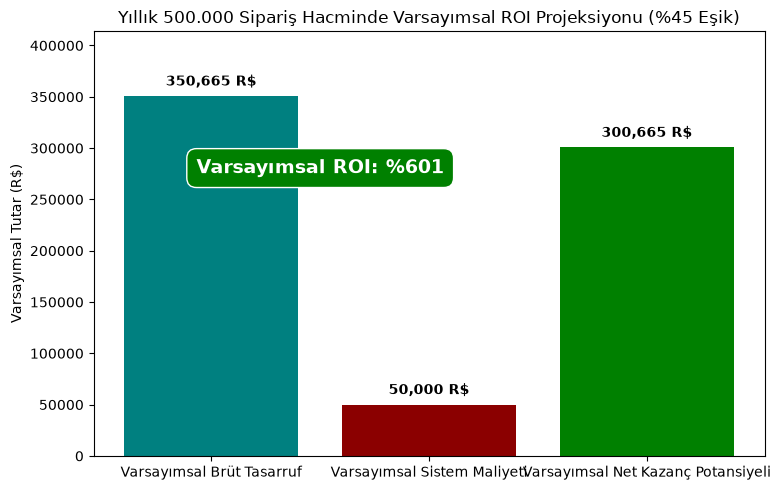

In [13]:
# 1. Test setindeki örnek sayısı (21.944) ve varsayımsal yıllık hacim (500.000)
test_order_count = len(y_test_c)
annual_order_volume = 500000
scale_factor = annual_order_volume / test_order_count

# 2. Yıllıklandırılmış Varsayımsal Projeksiyonlar (%45 Eşik Senaryosu)
annual_baseline_cost = baseline_cost * scale_factor
annual_ml_cost = ml_model_cost * scale_factor
annual_gross_savings = net_savings * scale_factor

# 3. Varsayımsal Yıllık Sistem/Teknoloji Gideri (50.000 R$)
annual_tech_cost = 50000
annual_net_profit = annual_gross_savings - annual_tech_cost
roi_percentage = (annual_net_profit / annual_tech_cost) * 100

print("--- YILLIK VARSAYIMSAL FİNANSAL PROJEKSİYON (500.000 Sipariş/Yıl Senaryosu) ---")
print(f"Yıllık Varsayımsal Memnuniyetsizlik/İade Zararı (Modelsiz): {annual_baseline_cost:,.0f} R$")
print(f"Yıllık ML Operasyonu + Telafi Müdahale Maliyeti: {annual_ml_cost:,.0f} R$")
print(f"YILLIK VARSAYIMSAL BRÜT TASARRUF POTANSİYELİ: +{annual_gross_savings:,.0f} R$\n")

print("--- VARSAYIMSAL YATIRIM GETİRİSİ (ROI PROJEKSİYONU) ---")
print(f"Varsayımsal Yıllık Teknoloji/Sistem Maliyeti: -{annual_tech_cost:,.0f} R$")
print(f"YILLIK VARSAYIMSAL NET KAZANÇ POTANSİYELİ: +{annual_net_profit:,.0f} R$")
print(f"VARSAYIMSAL YILLIK ROI PROJEKSİYONU: %{roi_percentage:,.0f}")

plt.figure(figsize=(8, 5))
bars = plt.bar(['Varsayımsal Brüt Tasarruf', 'Varsayımsal Sistem Maliyeti', 'Varsayımsal Net Kazanç Potansiyeli'], 
        [annual_gross_savings, annual_tech_cost, annual_net_profit], 
        color=['teal', 'darkred', 'green'])
plt.title('Yıllık 500.000 Sipariş Hacminde Varsayımsal ROI Projeksiyonu (%45 Eşik)')
plt.ylabel('Varsayımsal Tutar (R$)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (annual_gross_savings*0.02), 
             f"{yval:,.0f} R$", ha='center', va='bottom', fontweight='bold')
plt.text(0.5, annual_gross_savings * 0.8, f'Varsayımsal ROI: %{roi_percentage:,.0f}', 
         ha='center', va='center', fontsize=14, color='white', fontweight='bold',
         bbox=dict(facecolor='green', edgecolor='white', boxstyle='round,pad=0.5'))
plt.ylim(0, annual_gross_savings * 1.18)
plt.tight_layout()
plt.show()